# How has Netflix's catalogue strategy changed since 2015?

**Business question.** If you were advising a streaming competitor, what has Netflix been prioritising in
what it adds to its catalogue: movies or TV, which countries, which genres, new releases or back catalogue,
which audiences?

**Data.** `netflix_titles.csv` (Kaggle, Shivam Bansal): 8,807 titles available on Netflix in 2021, with the
date each was added. Additions run from 2008 to **25 September 2021**, so 2021 is a partial year.

**Key caveat: this is a snapshot, not a history.** It lists titles *still on Netflix in 2021*. Titles that were
added and later removed are missing, so earlier years are under-counted, especially licensed content, which
expires. Every trend below describes titles that survived to 2021, and the conclusions are worded that way.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG = Path('figures'); FIG.mkdir(exist_ok=True)

# One consistent, colourblind-safe palette for every chart
BLUE, ORANGE, AQUA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#9a9993', '#0b0b0b'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'axes.axisbelow': True,
                     'axes.titlelocation': 'left', 'axes.titlesize': 13, 'font.size': 10})

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=150, bbox_inches='tight'); plt.show()

df = pd.read_csv('netflix_titles.csv')
df.shape

(8807, 12)

## 1. Data quality checks and cleaning

In [2]:
# Dates have stray spaces (" August 4, 2017"); parse with an explicit format so bad values surface
df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), format='%B %d, %Y', errors='coerce')
print('Titles with no usable date_added:', df['date_added'].isna().sum())

# Three movies have their duration in the rating column (data-entry shift): move it back
shifted = df['rating'].str.contains('min', na=False)
print('Rows with duration in the rating column:', df.loc[shifted, ['title', 'rating', 'duration']].to_dict('records'))
df.loc[shifted, 'duration'] = df.loc[shifted, 'rating']
df.loc[shifted, 'rating'] = np.nan

print('Duplicate show_id:', df['show_id'].duplicated().sum(), '| duplicate title+type:', df.duplicated(['title', 'type']).sum())
df.isna().sum()

Titles with no usable date_added: 10
Rows with duration in the rating column: [{'title': 'Louis C.K. 2017', 'rating': '74 min', 'duration': nan}, {'title': 'Louis C.K.: Hilarious', 'rating': '84 min', 'duration': nan}, {'title': 'Louis C.K.: Live at the Comedy Store', 'rating': '66 min', 'duration': nan}]
Duplicate show_id: 0 | duplicate title+type: 0


show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             7
duration           0
listed_in          0
description        0
dtype: int64

In [3]:
df['year_added'] = df['date_added'].dt.year.astype('Int64')
df['content_age'] = df['year_added'] - df['release_year']   # years between release and arriving on Netflix

# Analyse 2015-2021: earlier years have too few surviving titles to compare shares
recent = df[df['year_added'].between(2015, 2021)].copy()
months_2021 = recent.loc[recent['year_added'] == 2021, 'date_added'].dt.month.max()
print(f"{len(recent):,} titles added 2015-2021; 2021 covers {months_2021} months")

8,741 titles added 2015-2021; 2021 covers 9 months


## 2. How fast is the catalogue growing, and is it shifting to TV?

In [4]:
by_type = pd.crosstab(recent['year_added'], recent['type'])
by_type['total'] = by_type.sum(axis=1)
by_type['tv_share_%'] = (by_type['TV Show'] / by_type['total'] * 100).round(1)
# 2021 is partial: annualise only for the growth comparison, never for shares
by_type['total_annualised'] = by_type['total'].astype(float)
by_type.loc[2021, 'total_annualised'] = round(by_type.loc[2021, 'total'] * 12 / months_2021)
by_type

type,Movie,TV Show,total,tv_share_%,total_annualised
year_added,,,,,
2015,56,26,82,31.7,82.0
2016,253,176,429,41.0,429.0
2017,839,349,1188,29.4,1188.0
2018,1237,412,1649,25.0,1649.0
2019,1424,592,2016,29.4,2016.0
2020,1284,595,1879,31.7,1879.0
2021,993,505,1498,33.7,1997.0


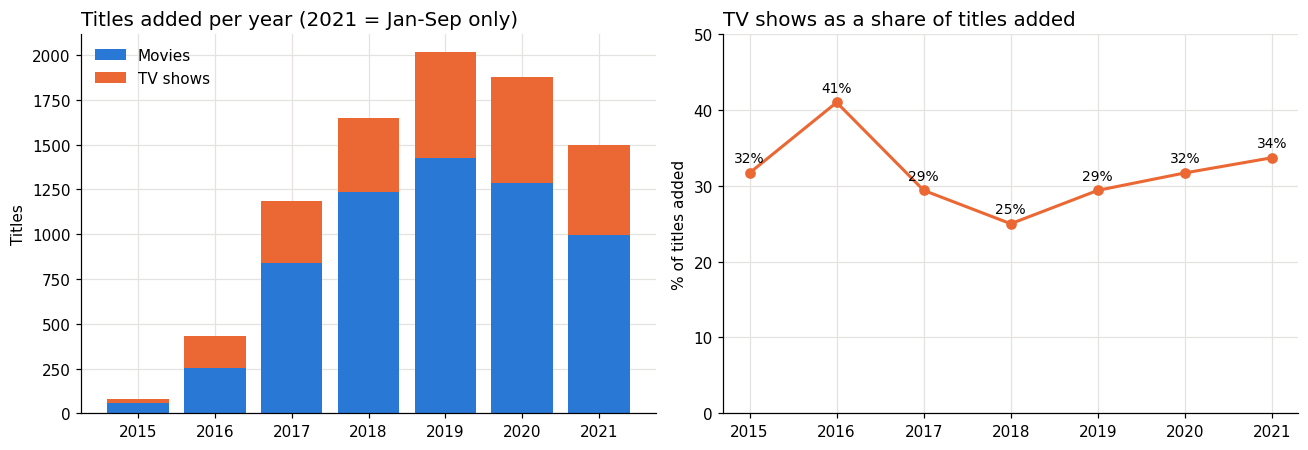

In [5]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2))
years = by_type.index.astype(int)
a.bar(years, by_type['Movie'], color=BLUE, label='Movies')
a.bar(years, by_type['TV Show'], bottom=by_type['Movie'], color=ORANGE, label='TV shows')
a.set_title('Titles added per year (2021 = Jan-Sep only)'); a.set_ylabel('Titles'); a.legend(frameon=False)
b.plot(years, by_type['tv_share_%'], color=ORANGE, lw=2, marker='o')
for x, v in zip(years, by_type['tv_share_%'], strict=True):
    b.annotate(f'{v:.0f}%', (x, v), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=9)
b.set_title('TV shows as a share of titles added'); b.set_ylabel('% of titles added'); b.set_ylim(0, 50)
save(fig, '01_growth_and_tv_share.png')

In [6]:
peak = by_type['total_annualised'].idxmax()
low_tv = by_type['tv_share_%'].idxmin()
print(f"Additions peaked in {peak} ({by_type.loc[peak, 'total']:,} titles); 2021 annualises to {by_type.loc[2021, 'total_annualised']:,.0f}.")
print(f"TV share fell to {by_type.loc[low_tv, 'tv_share_%']}% in {low_tv}, then rose to {by_type.loc[2021, 'tv_share_%']}% in 2021.")

Additions peaked in 2019 (2,016 titles); 2021 annualises to 1,997.
TV share fell to 25.0% in 2018, then rose to 33.7% in 2021.


## 3. Which countries is Netflix adding content from?

Many titles list several countries (`"United States, India"`). Counting only the first country, as is common, undercounts co-productions, so every listed country is counted here.

In [7]:
countries = (recent.assign(country=recent['country'].str.split(','))
             .explode('country'))
countries['country'] = countries['country'].str.strip().replace('', np.nan)
countries = countries.dropna(subset=['country'])
country_share = pd.crosstab(countries['year_added'], countries['country'], normalize='index') * 100
top = countries['country'].value_counts().head(6).index
country_share[top].loc[2016:].round(1)

country,United States,India,United Kingdom,Canada,France,Japan
year_added,,,,,,
2016,37.7,2.4,10.0,5.6,5.4,5.4
2017,32.8,11.5,9.5,5.0,3.8,2.6
2018,31.3,18.2,7.7,4.2,3.3,2.3
2019,37.8,9.6,8.4,3.7,3.5,3.3
2020,37.2,8.9,6.6,4.9,4.4,3.5
2021,42.7,7.1,8.2,4.0,4.1,3.6


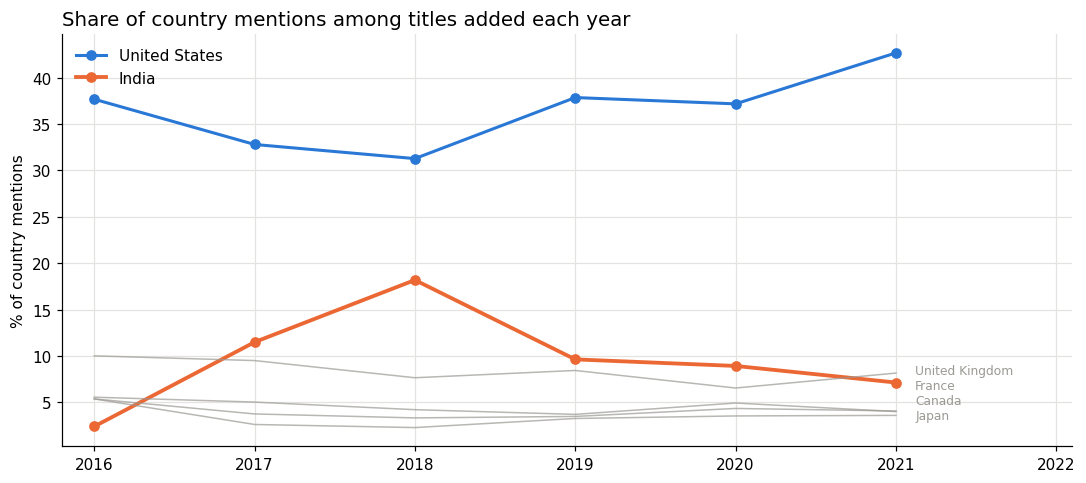

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
cs = country_share.loc[2016:]
ax.plot(cs.index, cs['United States'], color=BLUE, lw=2, marker='o', label='United States')
ax.plot(cs.index, cs['India'], color=ORANGE, lw=2.5, marker='o', label='India')
others = [c for c in top if c not in ('United States', 'India')]
for name in others:
    ax.plot(cs.index, cs[name], color=GREY, lw=1, alpha=0.7)
# Spread end labels at least 1.6 points apart so close lines stay readable
label_y, last = {}, None
for name in sorted(others, key=lambda n: cs[n].iloc[-1]):
    y = cs[name].iloc[-1] if last is None else max(cs[name].iloc[-1], last + 1.6)
    label_y[name] = last = y
for name, y in label_y.items():
    ax.annotate(name, (cs.index[-1], cs[name].iloc[-1]), xytext=(cs.index[-1] + 0.12, y), textcoords='data',
                fontsize=8, color=GREY, va='center')
ax.set_title('Share of country mentions among titles added each year'); ax.set_ylabel('% of country mentions')
ax.legend(frameon=False, loc='upper left'); ax.set_xlim(2015.8, 2022.1)
save(fig, '02_country_mix.png')

In [9]:
india = country_share['India']
print(f"India: {india.loc[2016]:.1f}% of country mentions in 2016 -> {india.loc[2018]:.1f}% in 2018 -> {india.loc[2021]:.1f}% in 2021")
print(f"United States: {country_share.loc[2018, 'United States']:.1f}% in 2018 -> {country_share.loc[2021, 'United States']:.1f}% in 2021")

India: 2.4% of country mentions in 2016 -> 18.2% in 2018 -> 7.1% in 2021
United States: 31.3% in 2018 -> 42.7% in 2021


## 4. Which genres are gaining and losing share?

In [10]:
genres = recent.assign(genre=recent['listed_in'].str.split(', ')).explode('genre')
genre_share = pd.crosstab(genres['year_added'], genres['genre'], normalize='index') * 100
# Compare 2016-17 with 2020-21 (two-year windows smooth out single-year noise)
change = (genre_share.loc[2020:2021].mean() - genre_share.loc[2016:2017].mean()).sort_values()
movers = pd.concat([change.head(5), change.tail(5)])
movers.round(2).rename('share change, percentage points')

genre
Documentaries              -5.00
Stand-Up Comedy            -2.65
International TV Shows     -2.13
Romantic TV Shows          -1.88
British TV Shows           -1.05
Children & Family Movies    1.24
Action & Adventure          2.12
Romantic Movies             2.20
Dramas                      3.29
Comedies                    3.36
Name: share change, percentage points, dtype: float64

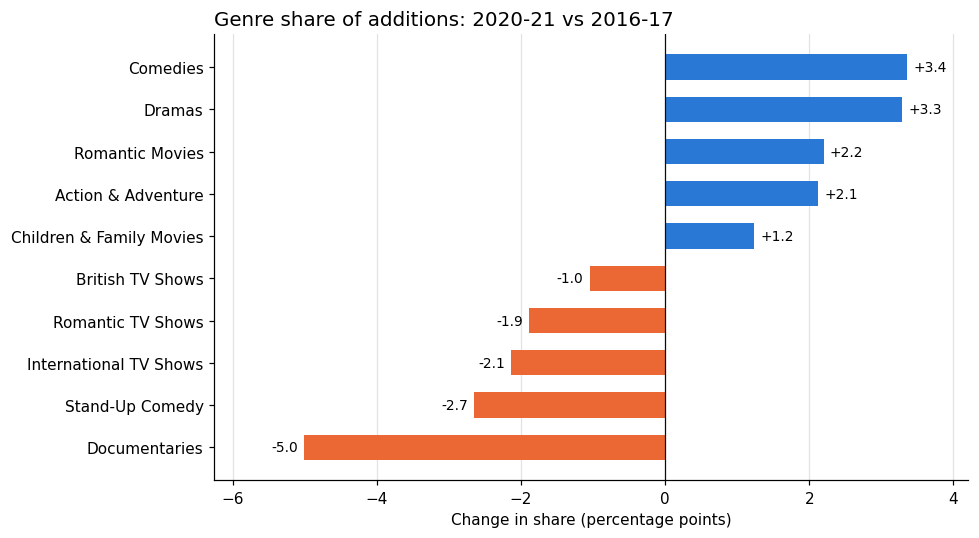

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(movers.index, movers.values, color=[ORANGE if v < 0 else BLUE for v in movers.values], height=0.6)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlim(movers.min() * 1.25, movers.max() * 1.25)
for y, v in enumerate(movers.values):
    ax.annotate(f'{v:+.1f}', (v, y), xytext=(4 if v > 0 else -4, 0), textcoords='offset points',
                ha='left' if v > 0 else 'right', va='center', fontsize=9)
ax.set_title('Genre share of additions: 2020-21 vs 2016-17'); ax.set_xlabel('Change in share (percentage points)')
ax.grid(axis='y', visible=False)
save(fig, '03_genre_movers.png')

## 5. New releases or back catalogue?

`content_age` is the gap between a title's release year and the year it arrived on Netflix. A title added the same or the following year is treated as a *fresh* release.

In [12]:
fresh = recent.assign(fresh=recent['content_age'] <= 1).groupby('year_added')['fresh'].mean() * 100
age_q = recent.groupby('year_added')['content_age'].quantile(0.75)
pd.DataFrame({'fresh_%': fresh.round(1), 'content_age_75th_pct': age_q})

,fresh_%,content_age_75th_pct
year_added,,
2015,81.7,1.0
2016,65.5,4.0
2017,59.8,3.0
2018,54.8,5.0
2019,51.6,6.0
2020,55.5,6.0
2021,50.8,8.0


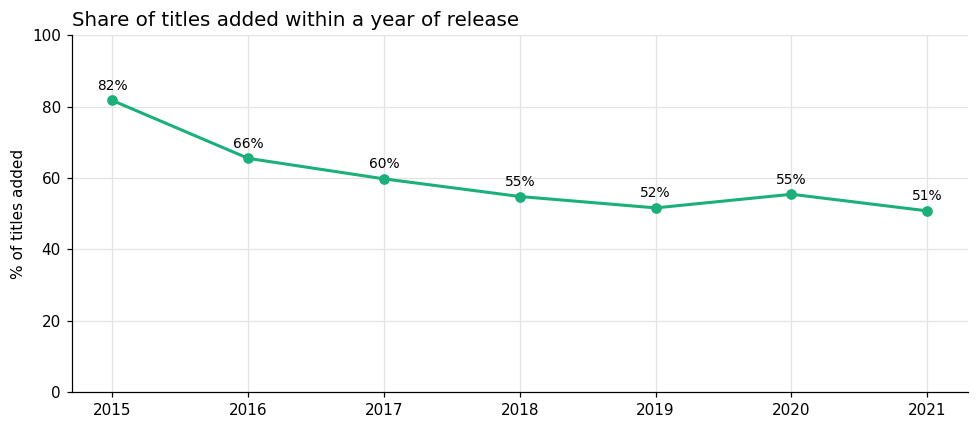

Fresh share: 82% (2015) -> 51% (2021)


In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(fresh.index, fresh.values, color=AQUA, lw=2, marker='o')
for x, v in fresh.items():
    ax.annotate(f'{v:.0f}%', (x, v), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=9)
ax.set_title('Share of titles added within a year of release'); ax.set_ylabel('% of titles added'); ax.set_ylim(0, 100)
save(fig, '04_fresh_vs_catalogue.png')
print(f"Fresh share: {fresh.loc[2015]:.0f}% (2015) -> {fresh.loc[2021]:.0f}% (2021)")

This is where the snapshot caveat matters most: licensed back-catalogue titles from 2015-2016 have had more time to expire and disappear from the data than recent ones, which would make early years look *fresher* than they really were. The fall is therefore likely real but its size is uncertain.

## 6. Who is the catalogue for?

In [14]:
KIDS = {'TV-Y', 'TV-Y7', 'TV-Y7-FV', 'TV-G', 'G', 'PG'}
MATURE = {'TV-MA', 'R', 'NC-17'}
audience = recent.assign(kids=recent['rating'].isin(KIDS), mature=recent['rating'].isin(MATURE))
audience = (audience.groupby('year_added')[['kids', 'mature']].mean() * 100).round(1)
audience.loc[2016:]

,kids,mature
year_added,,
2016,15.9,41.3
2017,10.7,43.2
2018,10.1,47.2
2019,11.8,46.9
2020,16.7,45.7
2021,16.7,45.3


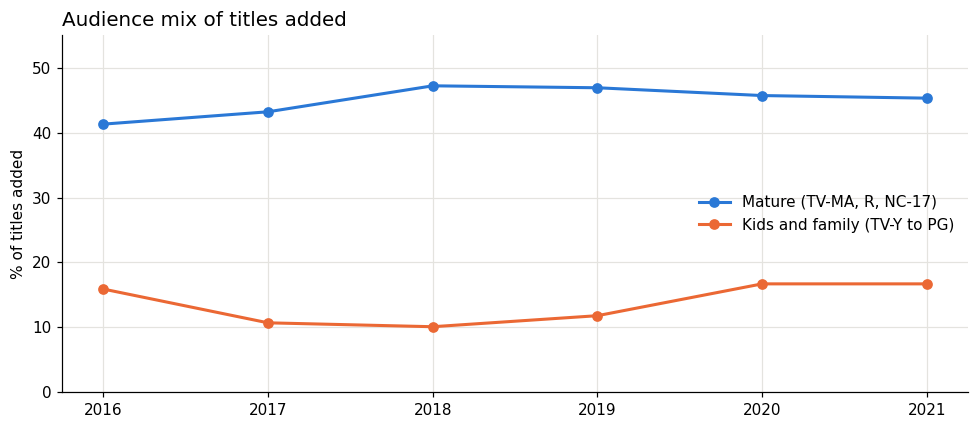

Kids share: 10.1% (2018) -> 16.7% (2021)


In [15]:
fig, ax = plt.subplots(figsize=(9, 4))
a = audience.loc[2016:]
ax.plot(a.index, a['mature'], color=BLUE, lw=2, marker='o', label='Mature (TV-MA, R, NC-17)')
ax.plot(a.index, a['kids'], color=ORANGE, lw=2, marker='o', label='Kids and family (TV-Y to PG)')
ax.set_title('Audience mix of titles added'); ax.set_ylabel('% of titles added'); ax.set_ylim(0, 55)
ax.legend(frameon=False, loc='center right')
save(fig, '05_audience_mix.png')
print(f"Kids share: {audience.loc[2018, 'kids']}% (2018) -> {audience.loc[2021, 'kids']}% (2021)")

## 7. Findings and recommendations

The numbers in this section are printed by the cells above; the README repeats them.

**What changed (among titles still on Netflix in 2021):**
1. **Growth has levelled off.** Additions climbed every year to a 2019 peak; 2020 was lower and 2021 is on a
   similar annualised pace. The catalogue is no longer in land-grab mode.
2. **A swing back towards TV.** TV's share of additions bottomed out in 2018 and has risen every year since.
   Series keep subscribers watching for months, which matters more once growth slows.
3. **India was a short, sharp bet.** Its share of country mentions jumped roughly sevenfold from 2016 to 2018,
   then fell back by more than half. The US share recovered over the same period.
4. **Comedies, dramas, romantic and action movies gained share; documentaries and stand-up lost the most.**
5. **More back catalogue.** The share of titles added within a year of release fell steadily, although the
   snapshot effect means the true decline is probably smaller than it looks.
6. **Kids content is back.** The kids-and-family share rose from its 2018 low, while mature content held steady.

**If I were advising a competing streamer:**
- Expect Netflix to compete on **series that retain subscribers** rather than raw title count; benchmark against
  TV hours, not catalogue size.
- **Regional bets are reversible.** Netflix pulled back from India after a big push; a competitor entering a
  market should plan for a multi-year commitment, not a launch spike.
- **Family content is a gap Netflix is closing**; a family-focused service should move before that advantage narrows.

**Limitations.** Snapshot data (removed titles are missing), additions are counts not viewing hours, and there is no
cost or audience data, so this shows *what Netflix added*, not *what worked*.